# Adaptive FPFS (`afpfs1`) on one isotropic isolated galaxy

One round exponential galaxy, sheared by $(g_1, g_2) = (0.02, 0.00)$, convolved with a Moffat PSF and
rendered noise-free.  The AnaCal detector's Gaussian fit (forced at the known centre) gives the galaxy's
intrinsic covariance and its shear response, which set the adaptive kernel size
$\sigma^2 = \sigma_0^2 + T/2$ (`FpfsConfig.adaptive_sigma`).  The fixed kernel `fpfs1`
($\sigma_0$) is measured alongside.

The shear estimate of a single galaxy is $\hat g_1 = e_1 / (\partial e_1 / \partial g_1)$.  The two biases
need two shear values, so the galaxy is rendered at $g_1 = \pm 0.02$:

$$ m_1 = \frac{\hat g_1(+0.02) - \hat g_1(-0.02)}{0.04} - 1, \qquad
   c_1 = \frac{\hat g_1(+0.02) + \hat g_1(-0.02)}{2}. $$

In [1]:
import anacal
import galsim
import matplotlib.pyplot as plt
import numpy as np

scale = 0.2          # arcsec / pixel
npix = 64            # stamp size
mag_zero = 30.0
sigma0 = 0.53        # fixed kernel and floor of the adaptive one [arcsec]
noise_variance = 1e-6   # noise-free image; a tiny variance keeps the estimators finite
g1_true = 0.02

## Render

AnaCal centres a stamp on pixel `(npix // 2, npix // 2)`; for an even `npix` GalSim draws there
after a shift of half a pixel.

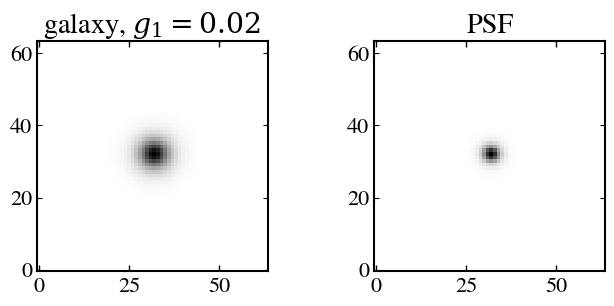

In [2]:
psf_obj = galsim.Moffat(beta=3.5, fwhm=0.7).shear(g1=0.02, g2=-0.01)
gal_obj = galsim.Exponential(half_light_radius=0.6, flux=4000.0)  # isotropic


def render(obj):
    return obj.shift(0.5 * scale, 0.5 * scale).drawImage(
        nx=npix, ny=npix, scale=scale
    ).array.astype(np.float64)


psf_array = render(psf_obj)
images = {
    g1: render(galsim.Convolve(gal_obj.shear(g1=g1, g2=0.0), psf_obj))
    for g1 in (+g1_true, -g1_true)
}

fig, axes = plt.subplots(1, 2, figsize=(7, 3.3))
axes[0].imshow(images[g1_true], origin="lower", cmap="gray_r")
axes[0].set_title(f"galaxy, $g_1 = {g1_true}$")
axes[1].imshow(psf_array, origin="lower", cmap="gray_r")
axes[1].set_title("PSF")
plt.tight_layout()

## The Gaussian fit at the known centre

`anacal.task.Task` with `force_center=True` fits the Gaussian model at the given position and returns
the intrinsic covariance `mxx, myy, mxy` with its shear responses (the `galRow` columns the adaptive
kernel reads, `anacal.fpfs.ADAPTIVE_FIT_COLUMNS`).

In [3]:
def fit_catalog(gal_array):
    x1 = np.array([npix // 2 * scale])
    x2 = np.array([npix // 2 * scale])
    det = anacal.table.make_catalog_empty(x1, x2)
    det["x1"], det["x2"] = x1, x2
    det["x1_det"], det["x2_det"] = x1, x2
    task = anacal.task.Task(
        scale=scale,
        sigma_arcsec=sigma0 / np.sqrt(2.0),
        snr_peak_min=5.0,
        omega_f=0.218,
        omega_v=0.011,
        stamp_size=npix,
        num_epochs=20,
        force_center=True,
        fpfs_c0=0.0,
    )
    cells = anacal.geometry.get_cell_list(
        img_nx=npix, img_ny=npix, cell_nx=npix, cell_ny=npix,
        cell_overlap=0, scale=scale,
    )
    cat = task.process_image(
        gal_array.astype(np.float32), psf_array,
        variance=noise_variance, cell_list=cells, detection=det,
    )
    assert len(cat) == 1
    out = np.zeros(
        1,
        dtype=[("y", "f8"), ("x", "f8")]
        + [(c, "f8") for c in anacal.fpfs.ADAPTIVE_FIT_COLUMNS],
    )
    out["y"] = cat["x2_det"] / scale
    out["x"] = cat["x1_det"] / scale
    for c in anacal.fpfs.ADAPTIVE_FIT_COLUMNS:
        out[c] = cat[c]
    return out


fits = {g1: fit_catalog(img) for g1, img in images.items()}
for g1, det in fits.items():
    tt = float(det["mxx"][0] + det["myy"][0])
    dtt = float(det["dmxx_dg1"][0] + det["dmyy_dg1"][0])
    print(f"g1 = {g1:+.2f}: T = mxx + myy = {tt:.4f} arcsec^2,  dT/dg1 = {dtt:+.4f}")

g1 = +0.02: T = mxx + myy = 0.3985 arcsec^2,  dT/dg1 = +0.0195
g1 = -0.02: T = mxx + myy = 0.3985 arcsec^2,  dT/dg1 = -0.0195


## Forced measurement: fixed `fpfs1`, adaptive `afpfs1` and `afpfs2` (kernel ratio 1.5)

In [4]:
fpfs_config = anacal.fpfs.FpfsConfig(
    sigma_shapelets1=sigma0,
    adaptive_sigma=True,   # adds afpfs1 (floor sigma0, cap 3 sigma0)
    adaptive_fpfs_kernel_ratio=1.5,   # adds afpfs2: sigma^2 = sigma0^2 + 1.5^2 T / 2
    shape_order=2,
)
KERNELS = ("fpfs1", "afpfs1", "afpfs2")
cats = {
    g1: anacal.fpfs.process_image(
        fpfs_config=fpfs_config,
        mag_zero=mag_zero,
        gal_array=images[g1],
        psf_array=psf_array,
        pixel_scale=scale,
        noise_variance=noise_variance,
        detection=fits[g1],
    )
    for g1 in images
}
cat = cats[g1_true]
print(f"columns: {len(cat.dtype.names)}  (fpfs1: 38, afpfs1: 41, afpfs2: 41)")
for k in ("afpfs1", "afpfs2"):
    print(f"{k} kernel size: {cat[k + '_sigma'][0]:.4f} arcsec "
          f"(fixed kernel {sigma0}), dsigma/dg1 = {cat[k + '_dsigma_dg1'][0]:+.4f}")
for k in KERNELS:
    print(f"{k:7s} e1 = {cat[k + '_e1'][0]:+.5f}   de1/dg1 = {cat[k + '_de1_dg1'][0]:.5f}   "
          f"S/N = {cat['s2n_' + k][0]:.1f}")

columns: 120  (fpfs1: 38, afpfs1: 41, afpfs2: 41)
afpfs1 kernel size: 0.6929 arcsec (fixed kernel 0.53), dsigma/dg1 = +0.0070
afpfs2 kernel size: 0.8539 arcsec (fixed kernel 0.53), dsigma/dg1 = +0.0129
fpfs1   e1 = +0.01153   de1/dg1 = 0.57613   S/N = 300043.6
afpfs1  e1 = +0.01072   de1/dg1 = 0.53582   S/N = 328252.1
afpfs2  e1 = +0.00962   de1/dg1 = 0.48056   S/N = 323752.0


## Multiplicative and additive bias

In [5]:
def shear_estimate(c, kernel):
    return c[f"{kernel}_e1"][0] / c[f"{kernel}_de1_dg1"][0]


for kernel in KERNELS:
    gp = shear_estimate(cats[+g1_true], kernel)
    gm = shear_estimate(cats[-g1_true], kernel)
    m1 = (gp - gm) / (2.0 * g1_true) - 1.0
    c1 = 0.5 * (gp + gm)
    print(f"{kernel:7s} g1_hat(+0.02) = {gp:+.6f}   g1_hat(-0.02) = {gm:+.6f}"
          f"   m1 = {m1:+.2e}   c1 = {c1:+.2e}")

fpfs1   g1_hat(+0.02) = +0.020006   g1_hat(-0.02) = -0.020006   m1 = +3.24e-04   c1 = -9.91e-09
afpfs1  g1_hat(+0.02) = +0.020008   g1_hat(-0.02) = -0.020008   m1 = +3.94e-04   c1 = -8.18e-09
afpfs2  g1_hat(+0.02) = +0.020009   g1_hat(-0.02) = -0.020009   m1 = +4.70e-04   c1 = -7.46e-09


Both kernels recover the shear of this galaxy to $|m_1| \lesssim 10^{-3}$ and $|c_1| \lesssim 10^{-8}$
(the residual $m_1$ is second order in $g$: one galaxy, no ring averaging).  The adaptive kernel is larger
than the fixed one because the galaxy's own size is added in quadrature.
